# Bahasa Isayrat
---
## 1. Business Understanding

### 1.1 Latar belakang, masalah, dan solusi
1. **Latar belakang**: Bahasa isayrat adalah bahasa yang menggunakan gerakkan tubuh (seperti gerakan tangan, kepala, dan sebagainya) untuk menyampaikan sesuatu pada penyandang tunarungu dan tunawicara.
2. **Masalah**: Banyak orang yang masih belum memahami bahasa isyarat, dan sulit memahami arti dari gerakan tubuhnya.
3. **Solusi**: Membuat model *machine learning* untuk mendeteksi gerakan tubuh (seperti gerakan tangan) untuk menerjemahkan ke bahasa isyarat secara otomatis.

---
## 2. Data Preprocessing

### 2.1 Import libray

In [89]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load dataset

In [90]:
df_train = pd.read_csv('Datafull .,train.csv', sep=';', na_values=['NA', 'N/A', 'NaN', '', ' '])
df_test = pd.read_csv('Datafull terakhir .,test.csv', sep=';')
df_train.columns = df_train.columns.str.strip()
df_test.columns = df_test.columns.str.strip()

### 2.3 Melihat kolom teratas dan kolom terbawah

In [91]:
df_train.head()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
0,449.894,638.530,329.537,588.029,262.366,475.709,253.967,343.421,247.663,236.477,...,475.346,591.398,426.475,592.339,341.419,548.671,413.658,541.039,454.239,NaN
1,459.426,638.641,347.614,599.550,273.522,486.969,262.374,354.810,248.102,248.011,...,471.021,587.605,425.540,598.047,337.165,559.660,410.858,548.164,455.238,A
2,444.194,659.268,326.598,616.910,253.226,497.914,243.082,361.876,239.491,259.676,...,476.613,560.803,418.030,567.584,346.090,533.656,416.844,524.283,450.811,A
3,443.780,650.429,324.970,607.825,252.818,487.201,244.345,356.561,243.655,256.638,...,473.187,573.173,418.568,580.205,339.026,541.187,411.295,528.062,445.777,A
4,452.860,638.769,340.436,595.407,272.323,487.497,254.365,357.569,231.482,241.993,...,463.566,577.341,425.073,581.486,337.553,551.375,410.228,546.574,449.936,A


In [92]:
df_test.head()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
0,449.429,643.857,327.271,587.170,265.731,484.233,246.689,362.602,231.657,252.290,...,480.806,582.295,427.375,587.343,339.388,547.296,415.208,536.242,454.387,NaN
1,451.351,653.700,333.252,594.944,265.111,486.310,256.936,354.813,248.984,239.251,...,491.502,598.279,438.230,609.486,345.403,559.002,414.437,543.311,457.700,A
2,457.565,692.363,335.312,635.283,267.992,518.501,261.948,388.552,264.993,288.713,...,490.838,584.324,453.037,589.529,370.452,548.982,435.461,536.997,465.605,A
3,454.034,534.794,333.222,489.421,258.394,399.013,232.771,269.755,218.668,160.658,...,358.808,537.166,308.455,531.600,212.394,505.065,284.374,499.484,329.256,A
4,449.840,545.633,327.645,504.473,256.748,405.653,228.244,273.756,210.097,166.311,...,365.462,545.115,312.461,548.587,221.122,514.636,287.484,503.828,326.010,A


In [93]:
df_train.tail()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
32844,438.216,475.728,384.271,438.175,365.128,370.238,359.100,308.232,341.079,263.943,...,393.282,526.248,369.550,542.888,314.872,553.693,291.555,565.394,270.450,Y
32845,451.700,471.125,388.505,420.364,370.429,366.011,359.194,301.358,338.958,255.391,...,394.962,523.331,378.997,544.635,321.277,556.352,292.890,574.840,273.024,Y
32846,461.909,469.288,400.524,424.948,372.224,372.311,353.600,310.913,326.736,261.919,...,394.474,534.607,373.414,555.518,319.473,570.948,285.517,586.932,256.553,Y
32847,451.633,470.803,393.561,427.040,365.993,371.472,349.987,306.755,324.605,257.534,...,390.126,524.399,378.125,548.321,321.545,566.286,289.032,585.819,261.687,Y
32848,446.508,479.837,383.399,422.028,364.069,359.685,355.280,293.822,331.258,249.500,...,394.919,523.860,381.711,546.956,325.058,560.955,297.564,581.282,276.208,Y


In [94]:
df_test.tail()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16y,17x,17y,18x,18y,19x,19y,20x,20y,char
8208,454.776,476.377,403.617,408.764,391.925,343.421,389.176,279.748,367.133,241.514,...,396.766,549.493,379.501,577.800,324.864,595.128,299.906,619.279,278.937,Y
8209,449.620,471.150,393.538,421.391,377.734,355.225,367.321,289.840,339.901,244.889,...,389.447,532.272,375.938,554.986,321.615,574.323,293.923,598.442,269.572,Y
8210,449.519,465.264,394.832,419.211,374.325,353.492,359.242,291.124,329.151,246.300,...,384.814,530.158,364.581,549.727,312.611,571.271,280.469,596.652,249.134,Y
8211,450.871,475.178,392.631,427.684,372.055,363.563,357.538,299.618,330.009,252.363,...,390.146,526.202,377.189,548.725,325.212,565.361,296.700,586.975,268.252,Y
8212,452.598,470.873,389.470,420.458,363.923,367.279,348.741,301.624,326.953,256.088,...,399.808,522.940,371.270,545.972,312.801,556.604,284.749,572.162,265.434,Y


### 2.4 Melihat informasi data train

In [95]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 32849 entries, 0 to 32848
Data columns (total 43 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0x      32849 non-null  float64
 1   0y      32849 non-null  float64
 2   1x      32849 non-null  float64
 3   1y      32849 non-null  float64
 4   2x      32849 non-null  float64
 5   2y      32849 non-null  float64
 6   3x      32849 non-null  float64
 7   3y      32849 non-null  float64
 8   4x      32849 non-null  float64
 9   4y      32849 non-null  float64
 10  5x      32849 non-null  float64
 11  5y      32849 non-null  float64
 12  6x      32849 non-null  float64
 13  6y      32849 non-null  float64
 14  7x      32849 non-null  float64
 15  7y      32849 non-null  float64
 16  8x      32849 non-null  float64
 17  8y      32849 non-null  float64
 18  9x      32849 non-null  float64
 19  9y      32849 non-null  float64
 20  10x     32849 non-null  float64
 21  10y     32849 non-null  float64
 22  11x     3

### 2.5 Memeriksa jumlah data, missing value, dan data duplikat pada dataset train

In [96]:
print(f'jumlah data: {df_train.size}')

print(f'jumlah missing value: {df_train.isnull().sum().sum()}')
print(f'--missing value per kolom--- \n{df_train.isnull().sum()[df_train.isnull().sum() > 0]}')

print(f'jumlah data duplikat: {df_train.duplicated().sum()}')

jumlah data: 1412507
jumlah missing value: 49
--missing value per kolom--- 
14x      2
14y      2
15x      2
15y      7
16x      2
16y      3
17x      5
17y      1
18y      1
char    24
dtype: int64
jumlah data duplikat: 23


---
## 3. Explaratory Data Analysis (EDA)

### 3.1 Melihat deskripsi data train

In [97]:
df_train.describe()

,0x,0y,1x,1y,2x,2y,3x,3y,4x,4y,...,16x,16y,17x,17y,18x,18y,19x,19y,20x,20y
count,32849.000000,32849.000000,32849.000000,32849.000000,32849.00000,32849.000000,32849.000000,32849.000000,32849.000000,32849.000000,...,32847.000000,32846.000000,32844.000000,32848.000000,32849.000000,32848.000000,32849.000000,32849.000000,32849.000000,32849.000000
mean,452.487562,475.714510,427.711225,445.098657,423.43866,400.280874,438.871542,362.268773,452.668220,338.853849,...,498.978343,364.348394,521.897306,387.946387,535.892408,354.024572,525.676819,358.802615,517.353640,365.814100
std,33.520120,52.909844,54.618299,52.776351,80.52885,69.214755,101.527047,93.655925,120.968362,114.740541,...,102.025223,118.615725,66.132425,73.711071,87.463863,96.457858,93.328696,103.021041,97.024746,110.399991
min,26.970000,0.000000,0.000000,0.000000,-30.64200,0.000000,-67.560000,0.000000,-95.991000,0.000000,...,-139.906000,7.845000,-49.063000,54.555000,-83.522000,35.426000,-92.401000,39.292000,-98.609000,45.460000
25%,441.028000,453.376000,391.581000,410.966000,365.05200,352.689000,367.965000,300.572000,374.013000,264.204000,...,452.645000,304.218000,493.478000,340.677750,494.840000,290.776000,483.768000,291.999000,475.193000,296.790000
50%,450.211000,468.697000,413.540000,436.465000,407.72500,383.968000,430.541000,337.837000,452.060000,310.332000,...,489.608000,365.309500,529.412000,371.636500,545.175000,329.886000,531.410000,341.738000,517.521000,359.703000
75%,461.090000,491.656000,463.077000,471.833000,479.73100,433.306000,506.223000,396.942000,530.462000,375.741000,...,543.359000,409.731500,559.936250,423.889000,589.752000,392.063000,577.235000,400.458000,567.809000,414.288000
max,846.956000,964.173000,822.414000,861.044000,835.39700,828.416000,854.552000,837.067000,898.948000,840.879000,...,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000,997.123000


### 3.2 Memeriksai outlier dengan IQR dan Z-Score

In [98]:
numeric_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
outliers = []

for col in numeric_cols:
    if col in df_train.columns:
        q1 = df_train[col].quantile(0.25)
        q3 = df_train[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
        median = df_train[col].median()
        mean = df_train[col].mean()
        std = df_train[col].std()
        z_score = (df_train[col] - mean) / std
        outlier_iqr = df_train[(df_train[col] < lower) | (df_train[col] > upper)]
        outlier_z = df_train[np.abs(z_score) > 3]

        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'q1': q1,
            'median': median,
            'q3': q3,
            'batas_bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z.shape[0],
        })

pd.DataFrame(outliers)

,nama kolom,mean,q1,median,q3,batas_bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,0x,452.487562,441.02800,450.2110,461.09000,410.935000,491.183000,2689,574
1,0y,475.714510,453.37600,468.6970,491.65600,395.956000,549.076000,3466,648
2,1x,427.711225,391.58100,413.5400,463.07700,284.337000,570.321000,439,332
3,1y,445.098657,410.96600,436.4650,471.83300,319.665500,563.133500,965,396
4,2x,423.438660,365.05200,407.7250,479.73100,193.033500,651.749500,220,195
5,2y,400.280874,352.68900,383.9680,433.30600,231.763500,554.231500,1364,248
6,3x,438.871542,367.96500,430.5410,506.22300,160.578000,713.610000,186,118
7,3y,362.268773,300.57200,337.8370,396.94200,156.017000,541.497000,2535,398
8,4x,452.668220,374.01300,452.0600,530.46200,139.339500,765.135500,220,64
9,4y,338.853849,264.20400,310.3320,375.74100,96.898500,543.046500,2907,496


### 3.3 Visualisasi outleir dengan boxplot

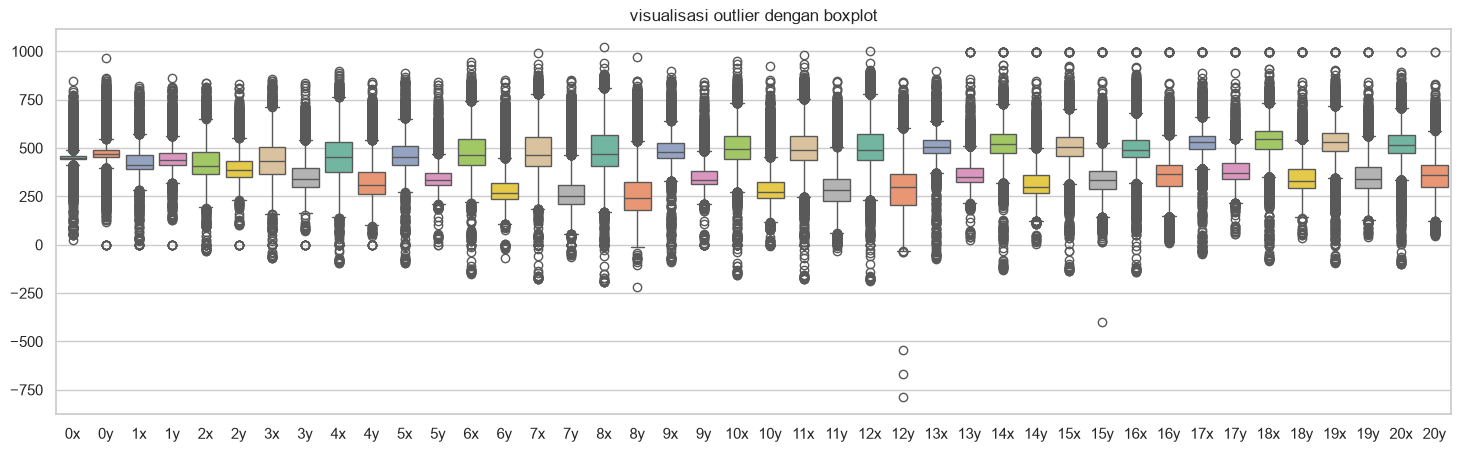

In [99]:
plt.figure(figsize=(18,5))
sns.boxplot(data=df_train, palette='Set2')
plt.title('visualisasi outlier dengan boxplot')
plt.show()

### 3.4 Visualisasi Distribusi data

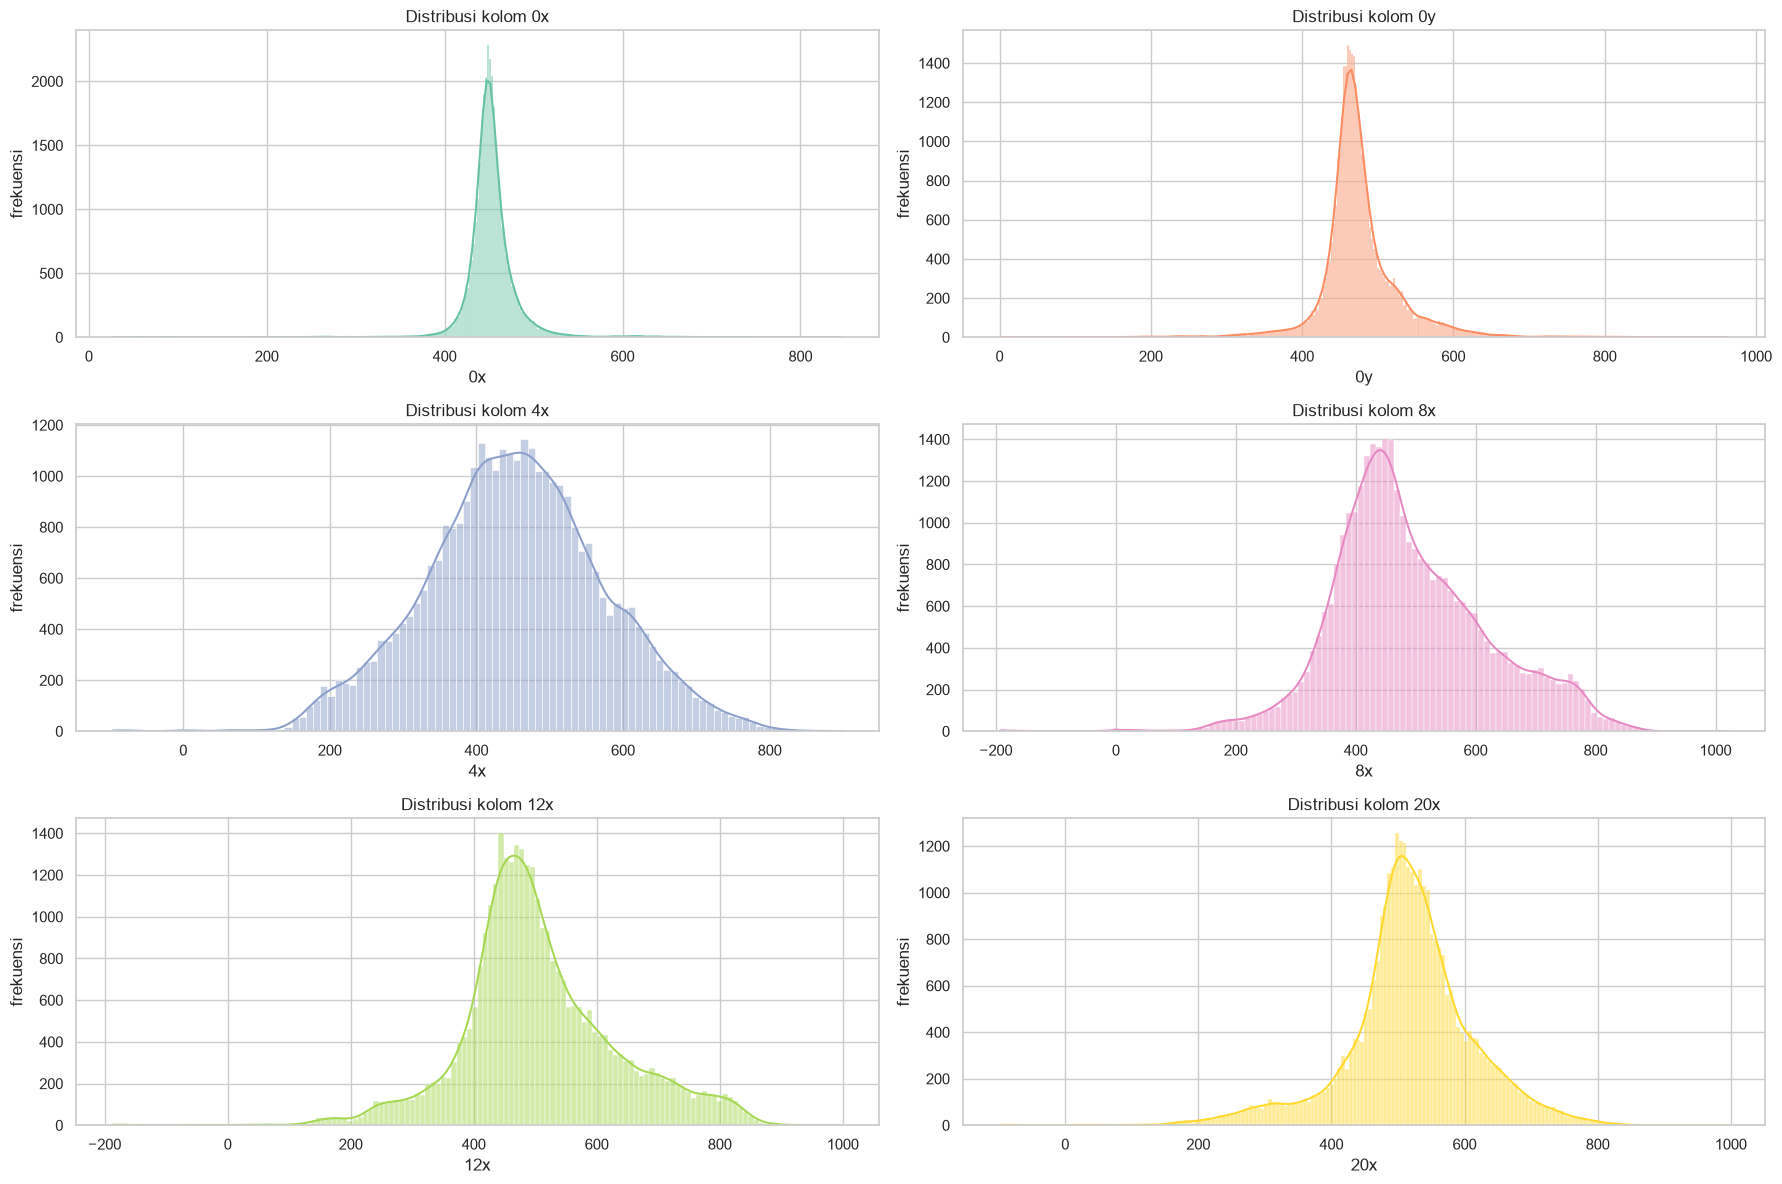

In [100]:
sample_cols = ['0x', '0y', '4x', '8x', '12x', '20x']
n_cols = 2
n_rows = int(len(sample_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
sns.set_theme(style='whitegrid')
colors = sns.color_palette('Set2', len(sample_cols))

for ax, col, c in zip(axes.flat, sample_cols, colors):
    sns.histplot(data=df_train, x=col, kde=True, color=c, ax=ax)
    ax.set(title=f'Distribusi kolom {col}', xlabel=col, ylabel='frekuensi')

for ax in axes.flat[len(sample_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

### 3.5 Visualisasi ditribusi kolom target

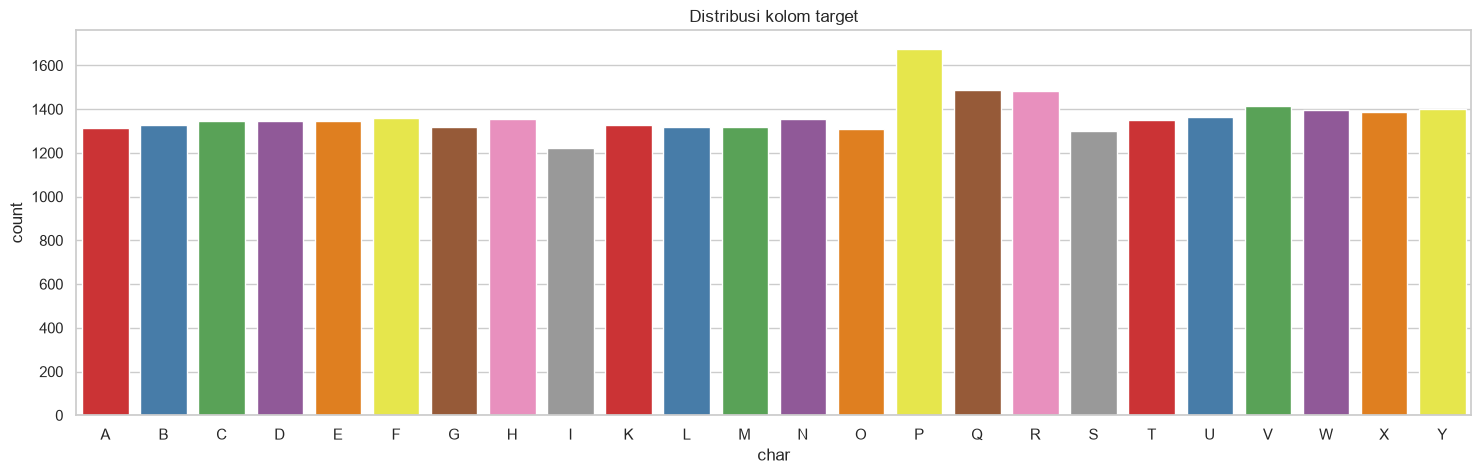

In [101]:
plt.figure(figsize=(18, 5))
sns.countplot(data=df_train, x='char', palette='Set1', hue='char', legend=False)
plt.title('Distribusi kolom target')
plt.show()

### 3.6 Visualisasi beberapa pasang koordinat dengan scatterplot

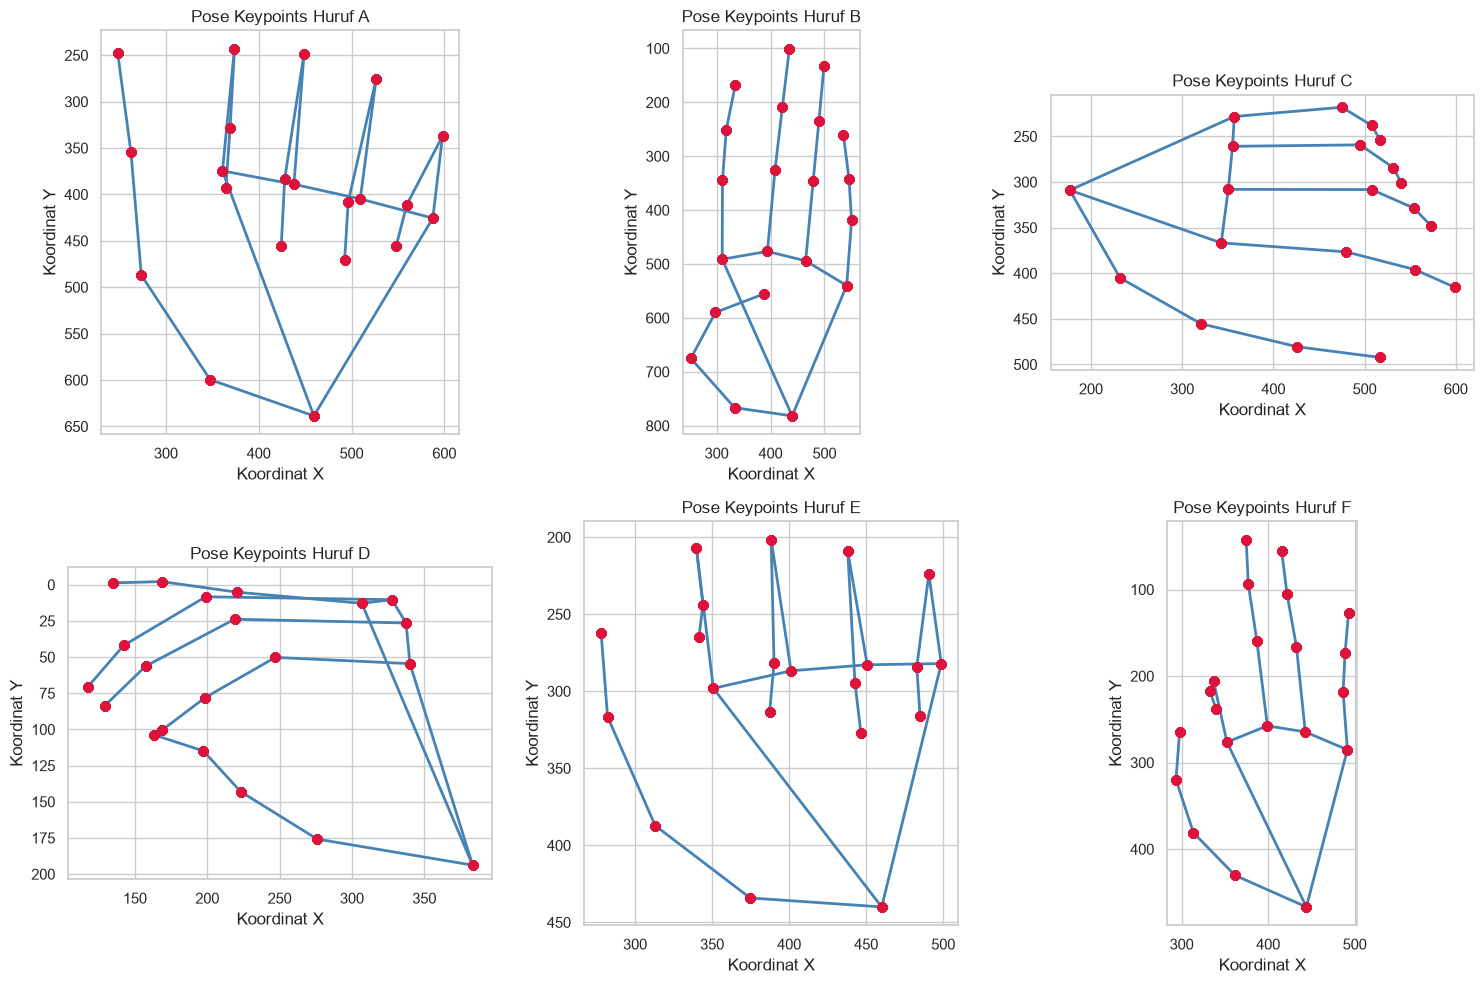

In [102]:
connections = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8), 
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (0, 17), (17, 18), (18, 19), (19, 20)
]


contoh_huruf = ['A', 'B', 'C', 'D', 'E', 'F']
fig, axes = plt.subplots(2, 3, figsize=(15, 10))


for ax, huruf in zip(axes.flat, contoh_huruf):
    sampel = df_train[df_train['char'] == huruf].iloc[0]
    xs = [sampel[f'{i}x'] for i in range(21)]
    ys = [sampel[f'{i}y'] for i in range(21)]
    for start, end in connections:
        ax.plot([xs[start], xs[end]], [ys[start], ys[end]], color='steelblue', linewidth=2)
        ax.scatter(xs, ys, color='crimson', s=40, zorder=5)
        ax.invert_yaxis()
        ax.set_aspect('equal')
        ax.set_title(f'Pose Keypoints Huruf {huruf}')
        ax.set_xlabel('Koordinat X')
        ax.set_ylabel('Koordinat Y')


plt.tight_layout()
plt.show()

---
## 4. Data Preprocessing

### 4.1 Menampilkan kembali missing value dan data duplikat

In [103]:
print(f'jumlah missing value: {df_train.isnull().sum().sum()}')
print(f'--missing value per kolom--- \n{df_train.isnull().sum()[df_train.isnull().sum() > 0]}')

print(f'jumlah data duplikat: {df_train.duplicated().sum()}')

jumlah missing value: 49
--missing value per kolom--- 
14x      2
14y      2
15x      2
15y      7
16x      2
16y      3
17x      5
17y      1
18y      1
char    24
dtype: int64
jumlah data duplikat: 23


### 4.2 Menghapus missing value dan data duplikat pada data train

In [104]:
df_train_clean = df_train.drop_duplicates().dropna().reset_index(drop=True)
df_test_clean = df_test.drop_duplicates().dropna().reset_index(drop=True)
print(f'ukuran data train setelah pembersihan: {df_train_clean.shape}')
print(f'ukuran data train setelah pembersihan: {df_test_clean.shape}')

ukuran data train setelah pembersihan: (32777, 43)
ukuran data train setelah pembersihan: (8173, 43)


### 4.3 Encoding pada kolom target

In [105]:
y_train_codes , unique = pd.factorize(df_train_clean['char'], sort=True)
y_train = pd.Series(y_train_codes, name='char')
y_test = pd.Series(pd.Categorical(df_test_clean['char'], categories=unique).codes, name='char')

### 4.3 Normalisasi posisi dan  skala tangan

In [106]:
def ekstrak_fitur_tangan(df_input):
    X_fe = df_input.drop(columns=['char']).copy()
    X_cols = [f'{i}x' for i in range(21)]
    y_cols = [f'{i}y' for i in range(21)]
    
    wrist_x = X_fe['0y'].copy()
    wrist_y = X_fe['0y'].copy()
    
    for col in X_cols:
        X_fe[col] = X_fe[col] - wrist_x
    for col in y_cols:
        X_fe[col] = X_fe[col] - wrist_y
        
    palm_size = np.sqrt(X_fe['9x']**2 + X_fe['9y']**2).replace(0, 1e-6)
    
    for col in X_cols + y_cols:
        X_fe[col] = X_fe[col] / palm_size
        
    return X_fe.drop(columns=['0x', '0y'])

X_train = ekstrak_fitur_tangan(df_train_clean)
X_test = ekstrak_fitur_tangan(df_test_clean)

### 4.4 Memisah data training dan data validasi

In [107]:
rng = np.random.default_rng(42)

splits = [np.split(rng.permutation(np.where(y_train == c)[0]), [int(0.8 * (y_train == c).sum())]) for c in np.unique(y_train)]

idx_tr = rng.permutation(np.concatenate([s[0] for s in splits]))
idx_val = rng.permutation(np.concatenate([s[1] for s in splits]))

X_val = X_train.iloc[idx_val].reset_index(drop=True)
y_val = y_train.iloc[idx_val].reset_index(drop=True)

X_train = X_train.iloc[idx_tr].reset_index(drop=True)
y_train = y_train.iloc[idx_tr].reset_index(drop=True)

### 4.5 Merubah tipe data ke numpy array

In [108]:
X_train_np = X_train.to_numpy(dtype='float')
X_test_np = X_test.to_numpy(dtype='float')
y_train_np = y_train.to_numpy(dtype='float')
y_test_np = y_test.to_numpy(dtype='float')

---

## 5. Modelling

### 5.1 Membangun Pohon

In [109]:
class LightGBM:
    def __init__(self, n_estimators=80, learning_rate=0.05, num_leaves=5, min_child_samples=10, lambda_reg=5.0, scale_pos_weight=1.0):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.num_leaves = num_leaves
        self.min_child_samples = min_child_samples
        self.lambda_reg = lambda_reg
        self.scale_pos_weight = scale_pos_weight

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def leaf_output(self, g, h):
        return -g.sum() / (h.sum() + self.lambda_reg)

    def cari_split(self, X, g, h, idx):
        G, H = g[idx].sum(), h[idx].sum()
        terbaik = (0, None, None)
        for f in range(X.shape[1]):
            for t in self.batas[f]:
                kiri = idx[X[idx, f] <= t]
                kanan = idx[X[idx, f] > t]
                if len(kiri) < self.min_child_samples or len(kanan) < self.min_child_samples: continue
                GL, HL = g[kiri].sum(), h[kiri].sum()
                GR, HR = G - GL, H - HL
                gain = 0.5 * (GL**2 / (HL + self.lambda_reg) + GR**2 / (HR + self.lambda_reg) - G**2 / (H + self.lambda_reg))
                if gain > terbaik[0]: terbaik = (gain, f, t)
        return terbaik

    def bangun_pohon(self, X, g, h):
        idx = np.arange(len(g))
        root = {"value": self.leaf_output(g, h)}
        gain, f, t = self.cari_split(X, g, h, idx)
        simpul = [(gain, f, t, root, idx)]
        jumlah_leaf = 1
        while jumlah_leaf < self.num_leaves:
            simpul.sort(key=lambda s: s[0])
            gain, f, t, node, idx = simpul.pop()
            if gain <= 0: break
            node["fitur"], node["batas"] = f, t
            kiri = X[idx, f] <= t
            for sisi, anak in [("kiri", idx[kiri]), ("kanan", idx[~kiri])]:
                node[sisi] = {"value": self.leaf_output(g[anak], h[anak])}
                gain, f2, t2 = self.cari_split(X, g, h, anak)
                simpul.append((gain, f2, t2, node[sisi], anak))
            jumlah_leaf += 1
        return root

    def prediksi_pohon(self, node, x):
        while "fitur" in node:
            if x[node["fitur"]] <= node["batas"]: node = node["kiri"]
            else: node = node["kanan"]
        return node["value"]

    def fit(self, X, y):
        bobot = np.where(y == 1, self.scale_pos_weight, 1.0)
        self.batas = [np.unique(np.percentile(X[:, f], range(5, 100, 5))) for f in range(X.shape[1])]
        p = np.sum(bobot * y) / np.sum(bobot)
        self.base_score = np.log(p / (1 - p))
        raw = np.full(len(y), self.base_score)
        self.trees = []
        for _ in range(self.n_estimators):
            p = self.sigmoid(raw)
            g = bobot * (p - y)
            h = bobot * p * (1 - p)
            pohon = self.bangun_pohon(X, g, h)
            self.trees.append(pohon)
            raw += self.learning_rate * np.array([self.prediksi_pohon(pohon, x) for x in X])
        return self

    def predict_prob(self, X):
        raw = np.full(len(X), self.base_score)
        for pohon in self.trees:
            raw += self.learning_rate * np.array([self.prediksi_pohon(pohon, x) for x in X])
        return self.sigmoid(raw)

    def predict(self, X):
        return (self.predict_prob(X) >= 0.5).astype(int)

### 5.2 Stratified Cross Validation & Melatih Model Pada Data Latih

In [110]:
np.random.seed(42)
y_train = y_train_np.astype(int)
y_test = y_test_np.astype(int)

fold = np.zeros(len(y_train), dtype=int)
for kelas in [0, 1]:
    idx = np.random.permutation(np.where(y_train == kelas)[0])
    fold[idx] = np.arange(len(idx)) % 5

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

oof_prob = np.zeros(len(y_train))
for i in range(5):
    val = fold == i
    model = LightGBM(scale_pos_weight=pos_weight).fit(X_train_np[~val], y_train[~val])
    oof_prob[val] = model.predict_prob(X_train_np[val])

final_model = LightGBM(scale_pos_weight=pos_weight).fit(X_train_np, y_train)
test_prob = final_model.predict_prob(X_test_np)

C:\Users\notebook\AppData\Local\Temp\ipykernel_24668\561305818.py:59: RuntimeWarning: invalid value encountered in log
  self.base_score = np.log(p / (1 - p))


---

## 6. Evaluation

### 6.1 Confusion Matrix, Evaluation Matrix, ROC-AUC, MCC

In [111]:
def roc_auc(y, prob):
    threshold = np.r_[np.inf, np.sort(prob)[::-1]]
    tpr = np.array([(prob[y == 1] >= x).mean() for x in threshold])
    fpr = np.array([(prob[y == 0] >= x).mean() for x in threshold])
    auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)
    return fpr, tpr, auc

def hitung_metrik(y, prob):
    pred = (prob >= 0.5).astype(int)
    tp = np.sum((y == 1) & (pred == 1))
    tn = np.sum((y == 0) & (pred == 0))
    fp = np.sum((y == 0) & (pred == 1))
    fn = np.sum((y == 1) & (pred == 0))

    bawah = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return {
        "Accuracy": (tp + tn) / len(y),
        "Precision": tp / max(tp + fp, 1),
        "Recall": tp / max(tp + fn, 1),
        "F1-Score": 2 * tp / max(2 * tp + fp + fn, 1),
        "ROC-AUC": roc_auc(y, prob)[2],
        "MCC": (tp * tn - fp * fn) / bawah if bawah > 0 else 0.0,
    }

hasil = {}
for i in np.unique(fold):
    hasil[f"Fold {i+1}"] = hitung_metrik(y_train[fold == i], oof_prob[fold == i])
hasil["Rata-rata"] = pd.DataFrame(hasil).mean(axis=1)
hasil["OOF Train"] = hitung_metrik(y_train, oof_prob)
hasil["Test Set"] = hitung_metrik(y_test, test_prob)
print(pd.DataFrame(hasil).T.round(4))

cm = np.zeros((2, 2), dtype=int)
for aktual, prediksi in zip(y_test, final_model.predict(X_test_np)):
    cm[aktual, prediksi] += 1

fpr, tpr, auc = roc_auc(y_test, test_prob)

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, color="navy", label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "r--")
plt.title("Kurva ROC (Test Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

           Accuracy  Precision  Recall  F1-Score  ROC-AUC     MCC
Fold 1       0.0170     0.9952  0.9858    0.9905   0.9997  0.9811
Fold 2       0.4976     0.0000  0.0000    0.0000   0.0000  0.0000
Fold 3       0.4976     0.0000  0.0000    0.0000   0.0000  0.0000
Fold 4       0.4964     0.0000  0.0000    0.0000   0.0000  0.0000
Fold 5       0.4964     0.0000  0.0000    0.0000   0.0000  0.0000
Rata-rata    0.4010     0.1990  0.1972    0.1981   0.1999  0.1962
OOF Train    0.0479     0.9952  0.1972    0.3291   0.0401  0.3276
Test Set     0.0399     0.0000  0.0000    0.0000   0.0000  0.0000


IndexError: index 2 is out of bounds for axis 0 with size 2

### 6.2 Noise Perturbation Testing

In [ ]:
std = X_train_np.std(axis=0)

hasil_noise = {}
for level in [0, 0.05, 0.10, 0.20]:
    X_noise = X_test_np + np.random.normal(0, level * std, X_test_np.shape)
    hasil_noise[f"{level:.0%}"] = hitung_metrik(y_test, final_model.predict_prob(X_noise))

noise_df = pd.DataFrame(hasil_noise).T
noise_df["Drop_Acc"] = noise_df["Accuracy"].iloc[0] - noise_df["Accuracy"]
print(noise_df.round(4))

noise_df[["Accuracy", "Recall", "F1-Score", "ROC-AUC"]].plot(marker="o", figsize=(8, 4))
plt.title("Noise Perturbation Testing")
plt.xlabel("Tingkat Noise")
plt.ylabel("Skor Metrik")
plt.show()

---

## 7. GUI

In [ ]:
import tkinter as tk

fitur = list(X_train.columns)

def prediksi_baru():
    try:
        x = np.array([[float(kotak.get()) for kotak in isian]])
    except ValueError:
        label_hasil.config(text="Semua kolom harus diisi angka")
        return
    prob = final_model.predict_prob(x)[0]
    label = final_model.predict(x)[0]
    label_hasil.config(text=f"Prediksi: {label}  (probabilitas kelas 1 = {prob:.2f})")

root = tk.Tk()
root.title("Prediksi LightGBM")

isian = []
for i, nama in enumerate(fitur):
    tk.Label(root, text=nama).grid(row=i, column=0, padx=10, pady=3, sticky="w")
    kotak = tk.Entry(root)
    kotak.grid(row=i, column=1, padx=10, pady=3)
    isian.append(kotak)

tk.Button(root, text="Prediksi", command=prediksi_baru).grid(row=len(fitur), column=0, columnspan=2, pady=8)
label_hasil = tk.Label(root, text="")
label_hasil.grid(row=len(fitur) + 1, column=0, columnspan=2, pady=5)

root.mainloop()